In [24]:
import pandas as pd

In [25]:
df=pd.read_csv('heart.csv')

In [26]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [27]:
df.shape

(303, 14)

In [28]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [30]:
df['trestbps']

0      145
1      130
2      130
3      120
4      120
      ... 
298    140
299    110
300    144
301    130
302    130
Name: trestbps, Length: 303, dtype: int64

In [31]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

In [32]:
df.rename(columns={"trestbps":"TBPS"},inplace=True)
df.rename(columns={"target":"OUTPUT"},inplace=True)
df.head(2)

,age,sex,cp,TBPS,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,OUTPUT
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1


In [33]:
df['OUTPUT'].value_counts()   #synthetic minority oversampling technique

OUTPUT
1    165
0    138
Name: count, dtype: int64

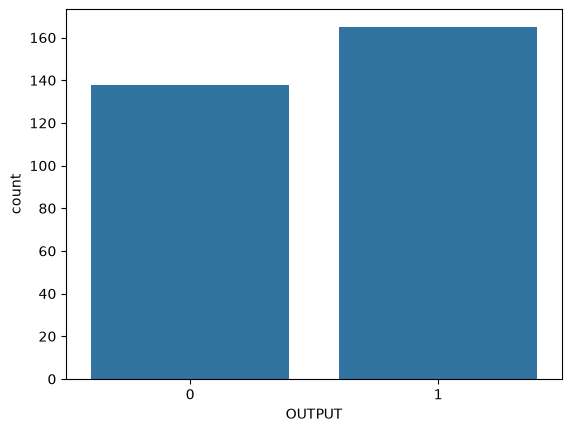

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=df["OUTPUT"])
plt.show()

In [35]:
#from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTE                                     #file
                                                                             #prefernce                                                                            # settings                                                                            #env(search)                                                                            #windows option click                                                                            #open("SCIPY_ARRAY_API":"1")
x=df.drop(columns="OUTPUT")
y=df["OUTPUT"]
#smote=SMOTE(sampling_strategy="minority")
smote= SMOTE(sampling_strategy="minority")                                 #pip install imbalanced-learn scikit-learn -y
x_sm,y_sm=smote.fit_resample(x,y)                                          ##reinstall with compatible version

                                                                           #pip install scikit-learn==1.3.2 imbalanced-learn==0.1                                                                       # reinstall kernal
                                                                           #from imblearn.over_sampling import SMOT                                                                          #print(imblearn._version_)
print(x_sm.shape)
print(y_sm.shape)

(330, 13)
(330,)


In [36]:
y_sm.value_counts()

OUTPUT
1    165
0    165
Name: count, dtype: int64

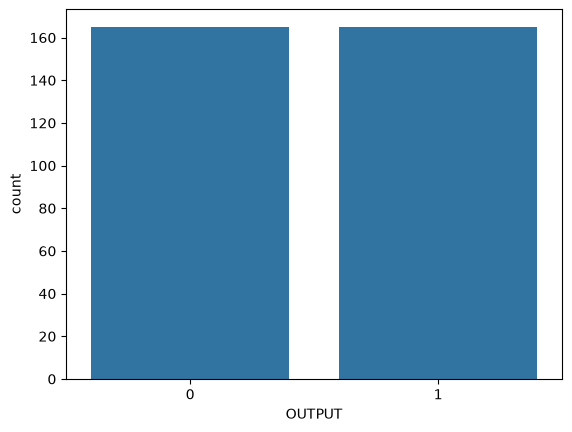

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x=y_sm)
plt.show()

In [38]:
from sklearn.preprocessing import MinMaxScaler  #StandardScaler
sc=MinMaxScaler()
c=sc.fit_transform(x_sm)
print(c)

[[0.70833333 1.         1.         ... 0.         0.         0.33333333]
 [0.16666667 1.         0.66666667 ... 0.         0.         0.66666667]
 [0.25       0.         0.33333333 ... 1.         0.         0.66666667]
 ...
 [0.64583333 0.         0.         ... 0.5        0.         0.66666667]
 [0.5        1.         0.         ... 0.5        0.5        0.66666667]
 [0.54166667 1.         0.         ... 0.5        0.25       1.        ]]


In [39]:
from sklearn.model_selection import train_test_split
x_smtrain,x_smtest,y_smtrain,y_smtest=train_test_split(x_sm,y_sm,test_size=0.20,random_state=4)
print(x_smtrain.shape)
print(x_smtest.shape)
print(y_smtrain.shape)
print(y_smtest.shape)
from sklearn.linear_model import LogisticRegression  #LinearRegression
lr=LogisticRegression()
lr.fit(x_smtrain,y_smtrain)
y_pred=lr.predict(x_smtrain)
y_pred

(264, 13)
(66, 13)
(264,)
(66,)


c:\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


array([1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0,
       0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1])

In [40]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report  #r2_score,mean_squared_error,mean_absolute_error
print(accuracy_score(y_smtrain,y_pred))
print(confusion_matrix(y_smtrain,y_pred))
print(classification_report(y_smtrain,y_pred))
#

0.8636363636363636
[[111  22]
 [ 14 117]]
              precision    recall  f1-score   support

           0       0.89      0.83      0.86       133
           1       0.84      0.89      0.87       131

    accuracy                           0.86       264
   macro avg       0.86      0.86      0.86       264
weighted avg       0.87      0.86      0.86       264

